In [1]:
%matplotlib inline
import numpy as np
import lightkurve as lk
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from astropy import units as u

/opt/anaconda3/lib/python3.12/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
search_result = lk.search_lightcurve('201637175', mission='K2')
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,K2 Campaign 01,2014,K2,1800,ktwo201637175,0.0
1,K2 Campaign 01,2014,EVEREST,1800,ktwo201637175,0.0
2,K2 Campaign 01,2014,K2SFF,1800,ktwo201637175,0.0
3,K2 Campaign 01,2014,K2VARCAT,1800,ktwo201637175,0.0


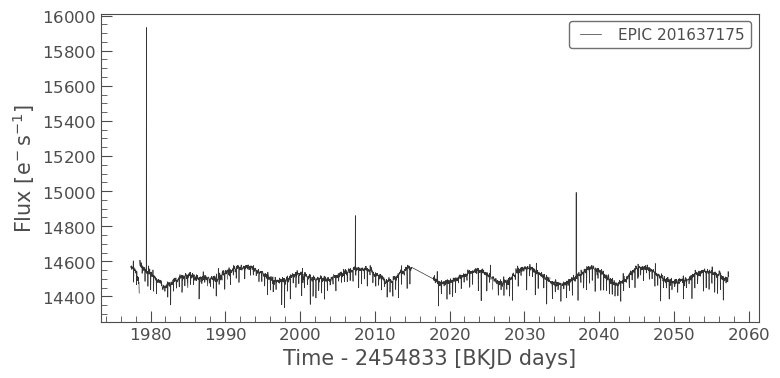

In [3]:
lc = search_result[0].download()
lc.plot() # native plot function in lightkurve
plt.show()

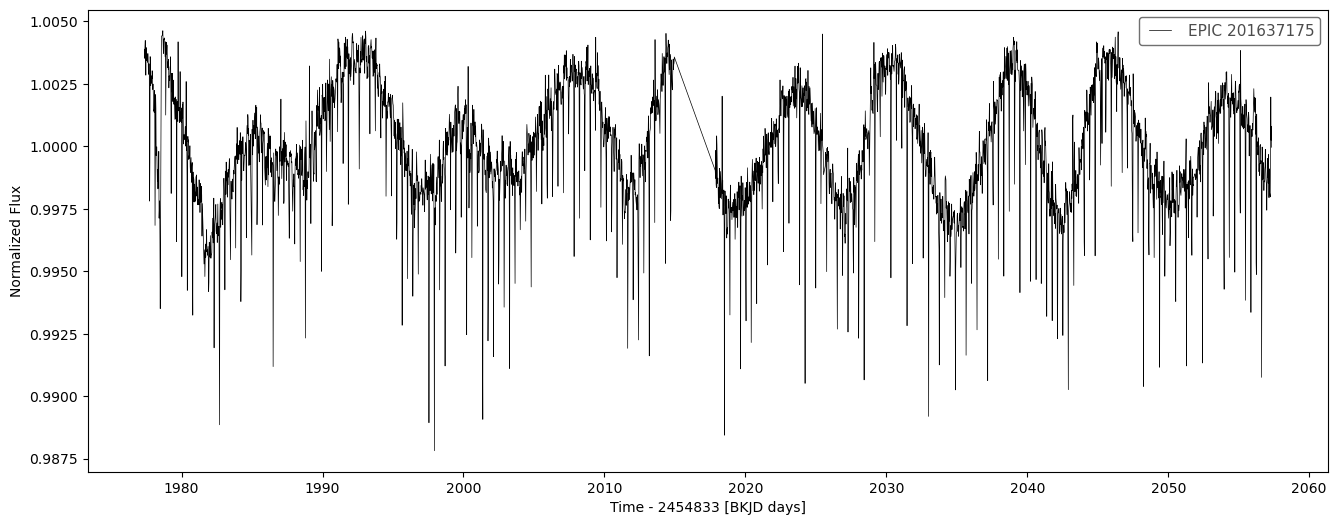

In [4]:
fig, ax = plt.subplots(figsize=(16,6))
lc = lc.remove_nans()
lc = lc.remove_outliers(sigma_upper = 2, sigma_lower = 1e9)
lc.normalize().plot(ax=ax, color='k')
plt.show()

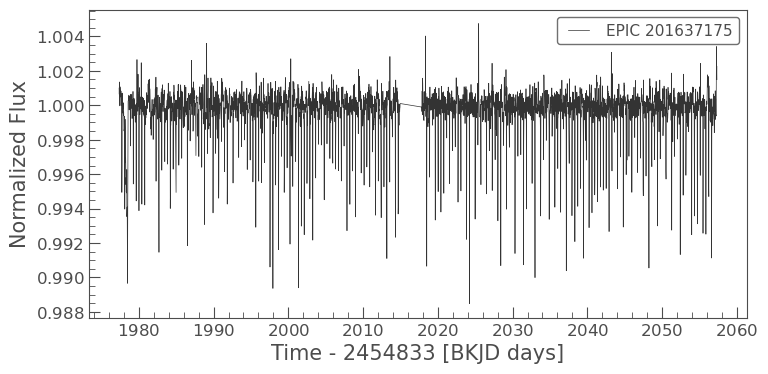

In [5]:
lc_flat = lc.flatten(window_length=101)

lc_flat.plot()
plt.show()

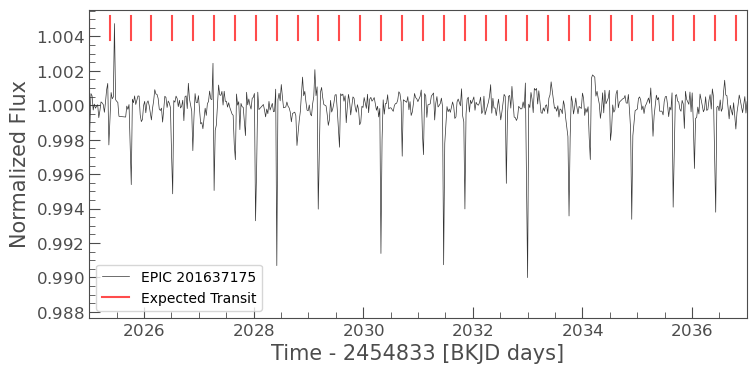

In [6]:
epoch = 1978.12
period = 9.1457/24

min_time, max_time = lc.time.value.min(), lc.time.value.max()
epochs = np.arange(int((min_time - epoch) / period) - 1, int((max_time - epoch) / period) + 2)
expected_transit_times = epoch + (epochs * period)

# Filter times to only those that fall within your data limits
expected_transit_times = expected_transit_times[
    (expected_transit_times >= min_time) & (expected_transit_times <= max_time)
]

# Plot the light curve and catch the Axes object
ax = lc_flat.plot()

# Loop through and add vertical lines at expected transit times
for t in expected_transit_times:
    ax.axvline(x=t, ymin=0.98, ymax=0.9, color='red', linestyle='-', alpha=0.7, label='Expected Transit')

# Prevent the legend from repeating the label
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys())

plt.xlim(2025, 2037)
plt.show()

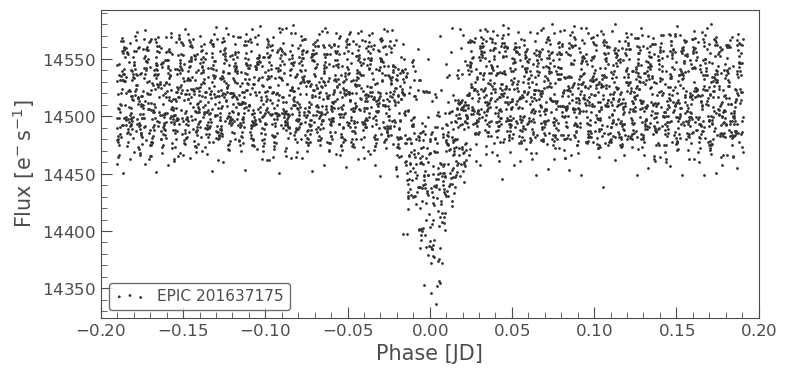

In [7]:
lc_folded = lc.fold(period = 9.1457/24, epoch_time = 1978.12)
lc_folded.scatter()
plt.xlim(-0.2,0.2)
plt.show()

In [29]:
P = 9.1457/24
T0 = 1978.12

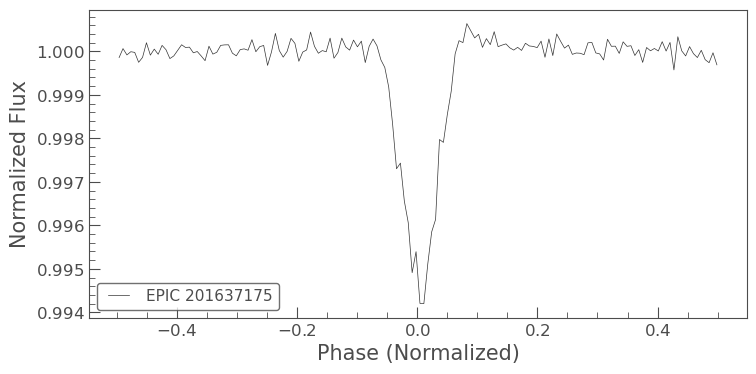

In [31]:
binned_lc = lc_flat.fold(period = P, epoch_time = T0, normalize_phase = True).bin(time_bin_size = 3.57 * u.min)
binned_lc.plot()
plt.show()

In [36]:
phase = binned_lc.phase.value
flux = binned_lc.flux.value

# sort points by orbital phase
idx = np.argsort(phase)
phase = phase[idx]
flux = flux[idx]

In [37]:
# organize sorted points to copy the style of the paper

# create two vertically stacked panels
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(6, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0}
)

# plot step-like light curves
for ax in (ax1, ax2):
    ax.step(
        phase, flux,
        where="mid",
        color="black",
        linewidth=0.8,
        label="Kepler Cadence"
    )

    # normalized flux baseline
    ax.axhline(1.0, color="red", linewidth=1.0)

    # ticks and borders
    ax.tick_params(
        axis="both", which="both",
        direction="in", top=True, right=True
    )
    ax.tick_params(which="major", length=7, width=1.0)
    ax.tick_params(which="minor", length=3.5, width=0.8)

    ax.xaxis.set_minor_locator(AutoMinorLocator(5))
    ax.yaxis.set_minor_locator(AutoMinorLocator(4))

    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    ax.set_xlim(-0.45, 0.45)

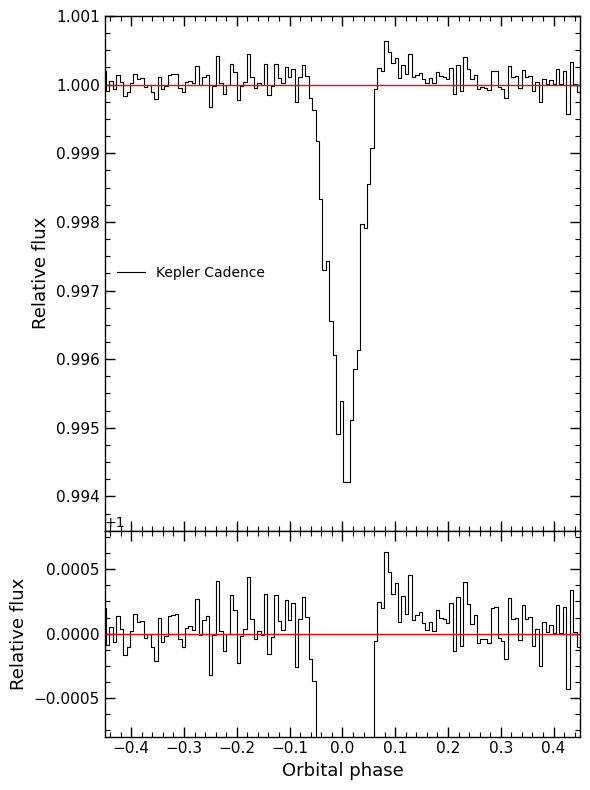

In [38]:
# actually plot the graphs

# upper panel: full transit
ax1.set_ylim(0.9935, 1.0010)
ax1.set_ylabel("Relative flux", fontsize=13)
ax1.legend(
    loc="center left",
    frameon=False,
    fontsize=10
)

# lower panel
ax2.set_ylim(0.9992, 1.0008)
ax2.set_ylabel("Relative flux", fontsize=13)
ax2.set_xlabel("Orbital phase", fontsize=13)

# hide upper panel x-axis labels
ax1.tick_params(axis="x", labelbottom=False)

# typography
for ax in (ax1, ax2):
    ax.tick_params(labelsize=11)

plt.tight_layout()
plt.subplots_adjust(hspace=0)
plt.show()